# Практика 8. Сегментация изображений

**Курс «Анализ изображений»**

В самостоятельной работе заполните ячейки с `TODO` и кратко объясните ошибки методов.  Для запуска после установки библиотек достаточно локальной среды.

**Маршрут:** пороги → связные области и водораздел → границы → кластеризация → активные контуры. Затем закрепим графовые методы и оценку качества.

## 0. Подготовка

Если библиотеки отсутствуют, установите их в текущем ядре через `%pip install numpy scipy matplotlib scikit-image opencv-python-headless`. В Colab обычно достаточно выполнить импорты ниже. Если `cv2` уже импортируется, переустанавливать OpenCV не нужно.

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from scipy import ndimage as ndi
from skimage import color, data, filters, measure, morphology, segmentation, transform, util

from skimage.feature import canny, peak_local_max

cv2.setNumThreads(1)

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

OpenCV: 5.0.0
NumPy: 2.4.6


In [ ]:
def show(*images, titles=None, cmaps=None, figsize=(14, 4), vmin=None, vmax=None):
    n = len(images)
    titles = titles or [""] * n
    cmaps = cmaps or [None] * n
    fig, axes = plt.subplots(1, n, figsize=figsize, squeeze=False)
    for ax, image, title, cmap in zip(axes[0], images, titles, cmaps):
        ax.imshow(image, cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def plot_labels(labels):
    # Для дискретных меток фиксируем цвет фона.
    return color.label2rgb(labels, bg_label=0, bg_color=(0, 0, 0))


def n_regions(labels):
    return np.count_nonzero(np.unique(labels) > 0)

## 1. Пороговая сегментация

Фиксированный порог выбирает пользователь. Метод Оцу (Отсу) автоматически ищет глобальный порог, максимизируя $w_0w_1(\mu_0-\mu_1)^2$. Здесь $w_i$ — доли пикселей, $\mu_i$ — средние яркости двух групп. Адаптивная бинаризация вычисляет порог отдельно для каждой окрестности пикселя.

Сравним методы на тёмном тексте. Добавим освещение с плавным перепадом, затем применим одинаковое правило «пиксель темнее порога — текст». Для локальных методов меняйте размер окна. Что происходит со штрихами и пустыми участками?

In [ ]:
def otsu_criterion(image):
    """Верните (t*, sigma_b2[0..254]) по гистограмме uint8-изображения."""
    image = np.asarray(image)
    hist = np.bincount(image.ravel(), minlength=256).astype(np.float64)
    p = hist / hist.sum()
    omega = np.cumsum(p)
    mu = np.cumsum(p * np.arange(256))
    mu_t = mu[-1]
    sigma_b2 = np.zeros(255, dtype=np.float64)
    for t in range(255):
        w0 = omega[t]
        w1 = 1.0 - w0
        if w0 < 1e-12 or w1 < 1e-12:
            continue
        mu0 = mu[t] / w0
        mu1 = (mu_t - mu[t]) / w1
        sigma_b2[t] = w0 * w1 * (mu0 - mu1) ** 2
    t_star = int(np.argmax(sigma_b2)) if np.count_nonzero(hist) > 1 else int(image.flat[0])
    return t_star, sigma_b2

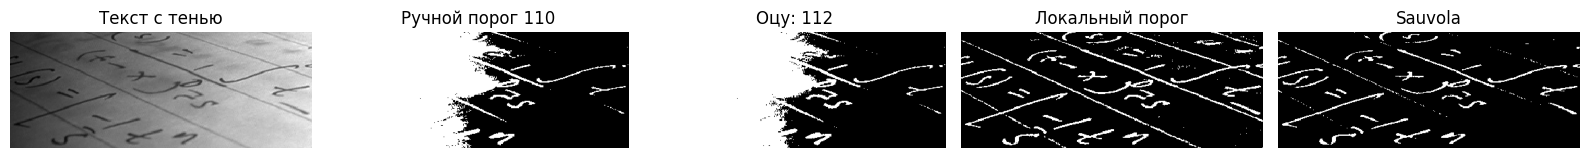

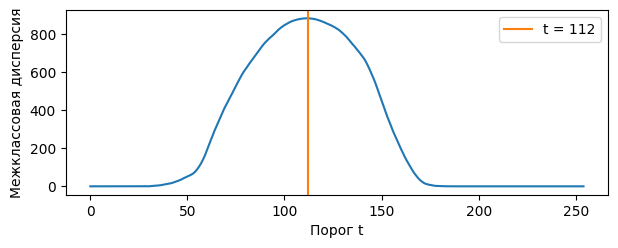

In [ ]:
text_image = util.img_as_float(data.text())
base = 0.24 + 0.62 * text_image
illumination = np.linspace(0.40, 1.15, base.shape[1])[None, :]
shadowed = util.img_as_ubyte(np.clip(base * illumination, 0, 1))

t_otsu, criterion = otsu_criterion(shadowed)
t_reference = filters.threshold_otsu(shadowed)
assert t_otsu == t_reference

window = 31
local = filters.threshold_local(shadowed, block_size=window, method="gaussian", offset=8)
sauvola = filters.threshold_sauvola(shadowed, window_size=window, k=0.18)
show(shadowed, shadowed <= 110, shadowed <= t_otsu, shadowed < local, shadowed < sauvola,
     titles=["Текст с тенью", "Ручной порог 110", f"Оцу: {t_otsu}", "Локальный порог", "Sauvola"],
     cmaps=["gray"] * 5, figsize=(16, 3.6))
fig, ax = plt.subplots(figsize=(7, 2.4))
ax.plot(criterion)
ax.axvline(t_otsu, color="tab:orange", label=f"t = {t_otsu}")
ax.set(xlabel="Порог t", ylabel="Межклассовая дисперсия")
ax.legend()
plt.show()

### Многоуровневый Оцу · дополнительно

Два порога дают три группы по яркости. Проверьте, оказываются ли пространственно разнесённые пиксели одной яркости в одной группе.

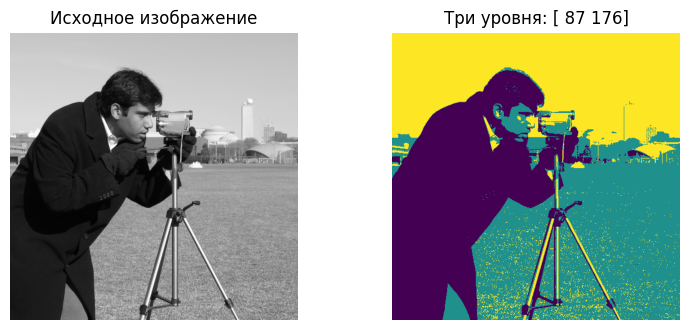

In [ ]:
camera = data.camera()
thresholds = filters.threshold_multiotsu(camera, classes=3)
# right=True оставляет значение, равное порогу, в нижнем интервале.
levels = np.digitize(camera, thresholds, right=True)
show(camera, levels, titles=["Исходное изображение", f"Три уровня: {thresholds}"],
     cmaps=["gray", "viridis"], figsize=(8, 3.4))

## 2. Методы на основе регионов

### 2.1. Связные компоненты и разрастание области

На бинарной маске при 4-связности соседями считаются пиксели с общей стороной. При 8-связности учитываются и диагонали. При разрастании область начинается с затравки. Соседа добавляем, если он проходит заданный критерий однородности.

На градациях серого используем простой вариант `flood` с фиксированным допуском относительно яркости затравки. Одинаково яркий остров за тёмной полосой показывает роль связности.

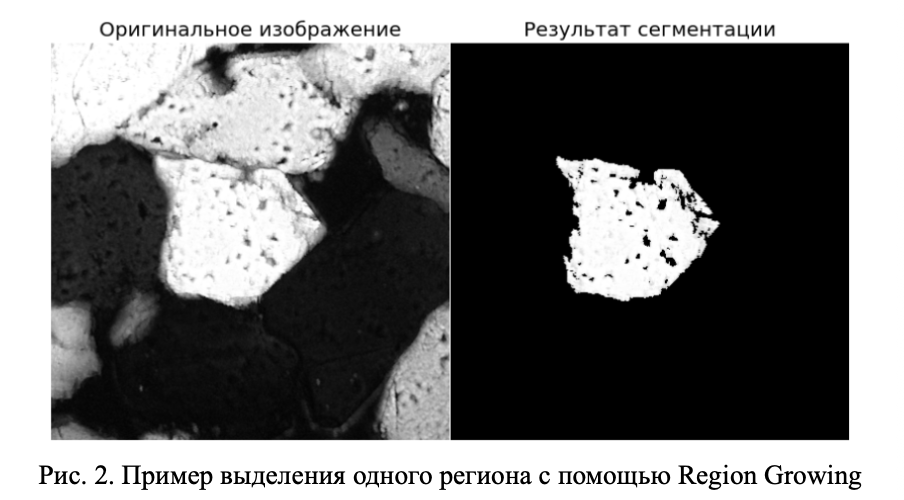

4-связность: 2 компоненты. 8-связность: 1 компонента.


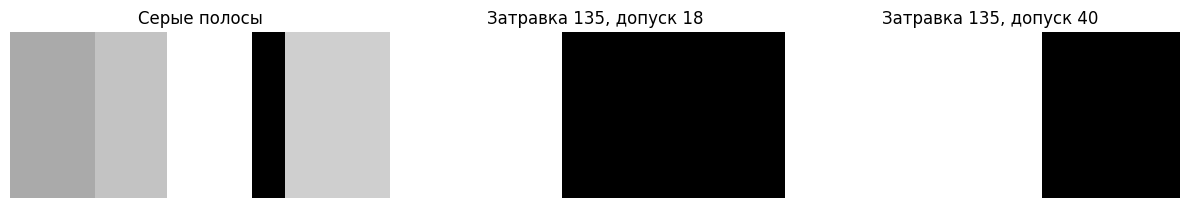

In [ ]:
diagonal = np.eye(2, dtype=bool)
labels4 = measure.label(diagonal, connectivity=1)
labels8 = measure.label(diagonal, connectivity=2)
assert (n_regions(labels4), n_regions(labels8)) == (2, 1)
print("4-связность: 2 компоненты. 8-связность: 1 компонента.")

strip = np.tile(np.repeat([135, 145, 170, 65, 150], [18, 15, 18, 7, 22]), (35, 1)).astype(np.uint8)
seed = (17, 8)  # строка, столбец
small_region = segmentation.flood(strip, seed, connectivity=1, tolerance=18)
large_region = segmentation.flood(strip, seed, connectivity=1, tolerance=40)
show(strip, small_region, large_region,
     titles=["Серые полосы", "Затравка 135, допуск 18", "Затравка 135, допуск 40"],
     cmaps=["gray"] * 3, figsize=(12, 2.7))

### 2.2. Split-and-Merge · дополнительно

Начните со всего изображения. Если разброс яркости в блоке выше допуска, делите блок на четыре. После разбиения объединяйте соседние блоки, пока их объединение проходит тот же критерий. Для разброса можно взять $\max I - \min I$.

Разбейте матрицу ниже на квадранты при допуске 8. Какие квадранты можно объединить при 4-связности? Что изменится при допуске 3?

```text
20 22 | 25 26
21 23 | 25 27
------+------
80 81 | 82 83
80 82 | 83 84
```

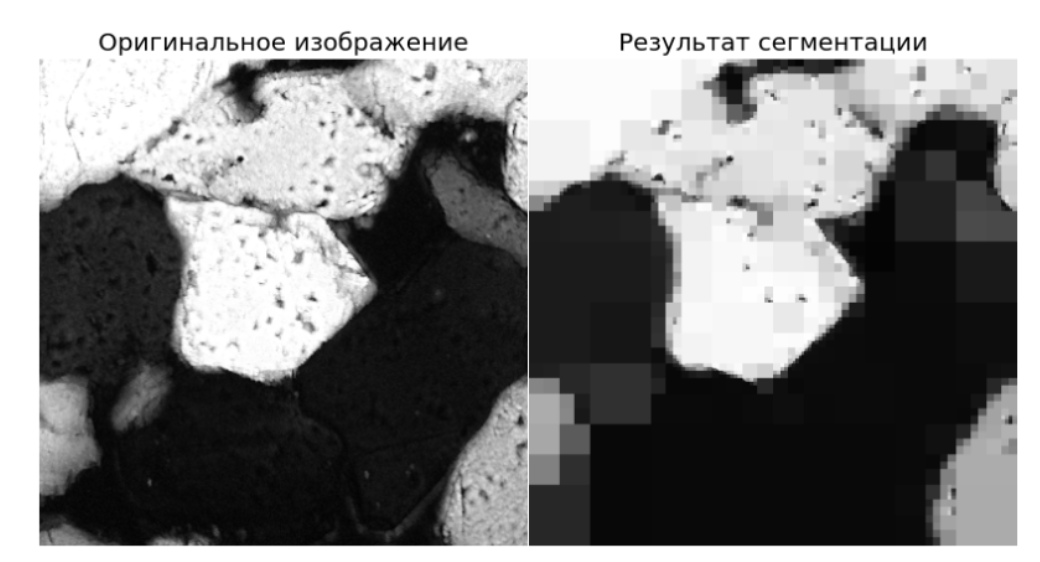

### 2.3. Водораздел по карте расстояний

Два перекрывающихся диска дают одну связную компоненту. Вычислим евклидово расстояние $D$ от каждого пикселя маски до фона. Максимумы $D$ станут маркерами. Для водораздела берём $-D$, чтобы центры объектов стали минимумами рельефа. Рост областей ограничиваем маской.

Увеличьте `min_distance` до 40. Что произойдёт с числом маркеров и объектов? Изменится ли бинарная маска переднего плана?

Связные компоненты: 1. Области watershed: 2.


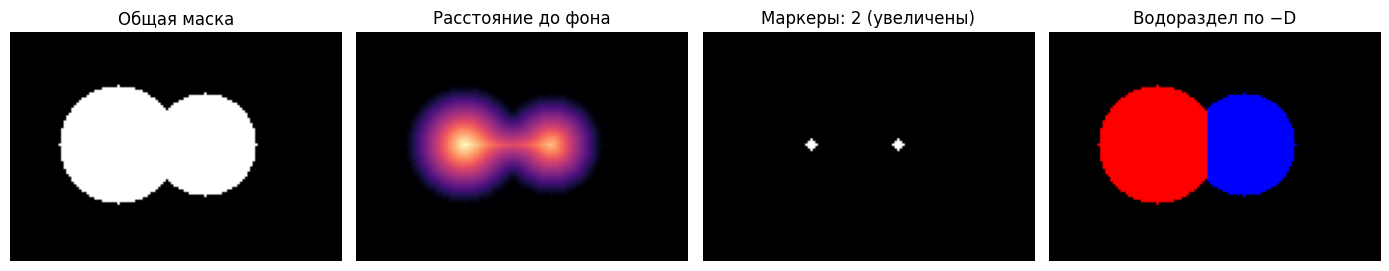

In [ ]:
def watershed_from_peaks(mask, distance, coords):
    markers = np.zeros(mask.shape, dtype=np.int32)
    markers[tuple(coords.T)] = np.arange(1, len(coords) + 1)
    labels = segmentation.watershed(-distance, markers=markers, mask=mask)
    return labels, markers

yy, xx = np.ogrid[:90, :130]
disk_a = (yy - 44) ** 2 + (xx - 42) ** 2 <= 23 ** 2
disk_b = (yy - 44) ** 2 + (xx - 76) ** 2 <= 20 ** 2
touching = disk_a | disk_b
distance = ndi.distance_transform_edt(touching)
min_distance = 8
coords = peak_local_max(distance, labels=touching, min_distance=min_distance, exclude_border=False)
labels_ws, markers = watershed_from_peaks(touching, distance, coords)
print(f"Связные компоненты: {n_regions(measure.label(touching))}. Области watershed: {n_regions(labels_ws)}.")
marker_display = ndi.binary_dilation(markers > 0, iterations=2)
show(touching, distance, marker_display, plot_labels(labels_ws),
     titles=["Общая маска", "Расстояние до фона", f"Маркеры: {len(coords)} (увеличены)", "Водораздел по −D"],
     cmaps=["gray", "magma", "gray", None])

## 3. Методы на основе границ

На `coins` яркость монет и фона частично совпадает. Сравним три способа получить маску: Оцу, заполнение замкнутых границ Кэнни и маркерный водораздел по модулю градиента Собеля. Карта Кэнни показывает границы, а заполнение превращает замкнутые контуры в области.

Для водораздела сначала посмотрим число областей без заданных маркеров. Затем зададим метку 1 уверенно тёмному фону и метку 2 ярким участкам монет. Здесь обе стартовые метки описывают категории «фон / монеты». Разделение отдельных монет потребовало бы проверки компонент или построения отдельных маркеров.

Областей без заданных маркеров: 17524


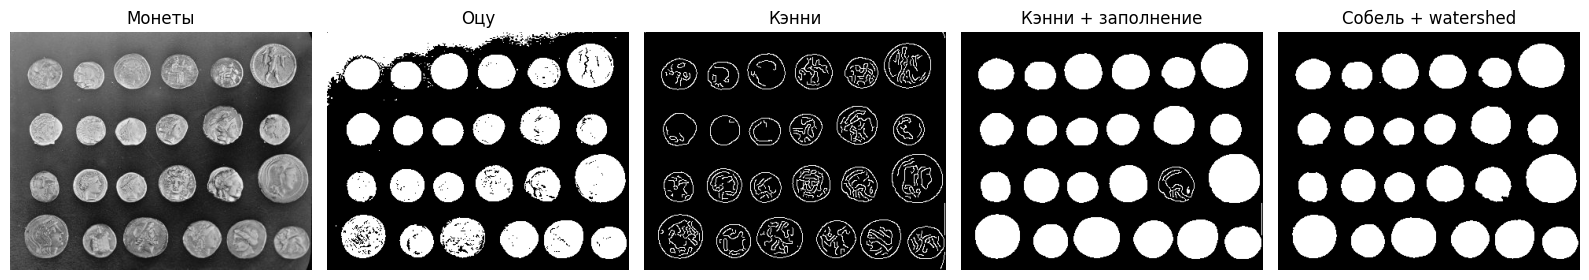

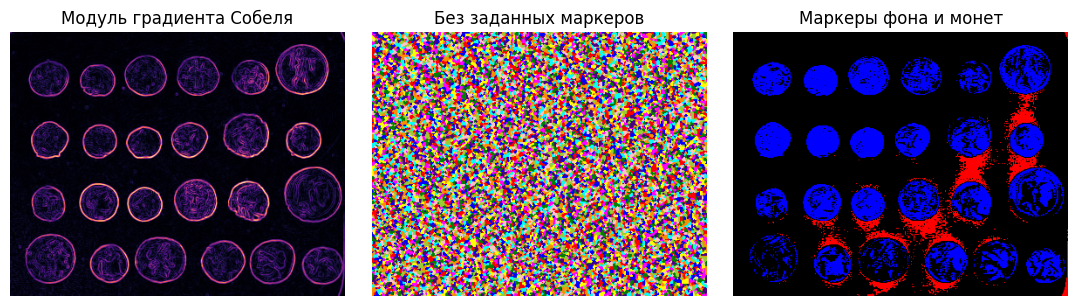

In [ ]:
coins = data.coins()
coins_float = util.img_as_float(coins)
coins_otsu = coins > filters.threshold_otsu(coins)
edges = canny(coins_float, sigma=1.5)
filled = ndi.binary_fill_holes(edges)
filled = measure.label(filled)
sizes = np.bincount(filled.ravel())
keep = sizes >= 25
keep[0] = False
edge_mask = keep[filled]

gradient = filters.sobel(coins_float)
raw_labels = segmentation.watershed(gradient)
coin_markers = np.zeros(coins.shape, dtype=np.int32)
coin_markers[coins < 30] = 1
coin_markers[coins > 150] = 2
coins_ws = segmentation.watershed(gradient, markers=coin_markers) == 2
coins_ws = ndi.binary_fill_holes(coins_ws)

print(f"Областей без заданных маркеров: {n_regions(raw_labels)}")
show(coins, coins_otsu, edges, edge_mask, coins_ws,
     titles=["Монеты", "Оцу", "Кэнни", "Кэнни + заполнение", "Собель + watershed"],
     cmaps=["gray"] * 5, figsize=(16, 3))
show(gradient, plot_labels(raw_labels), plot_labels(coin_markers),
     titles=["Модуль градиента Собеля", "Без заданных маркеров", "Маркеры фона и монет"],
     cmaps=["magma", None, None], figsize=(11, 3))

**Обсудите.** Где у Кэнни остался разрыв? Что произойдёт, если порог уверенного переднего плана уменьшить со 150 до 110? Объясните, почему маркер на фоне не сможет сменить метку при затоплении.

## 4. Кластеризация и суперпиксели

K-means группирует пиксели по цвету. Одна метка кластера может встречаться в нескольких несвязанных местах. SLIC учитывает цвет и положение пикселя. С увеличением `compactness` пространственная близость получает больший вес. Суперпиксели дают множество небольших областей, которыми затем можно описывать границы объекта.

На одном фрагменте сравните число цветов k-means, число его связных участков и границы SLIC при двух значениях компактности.

K-means: 4 цветовых кластера, 562 связных участков.


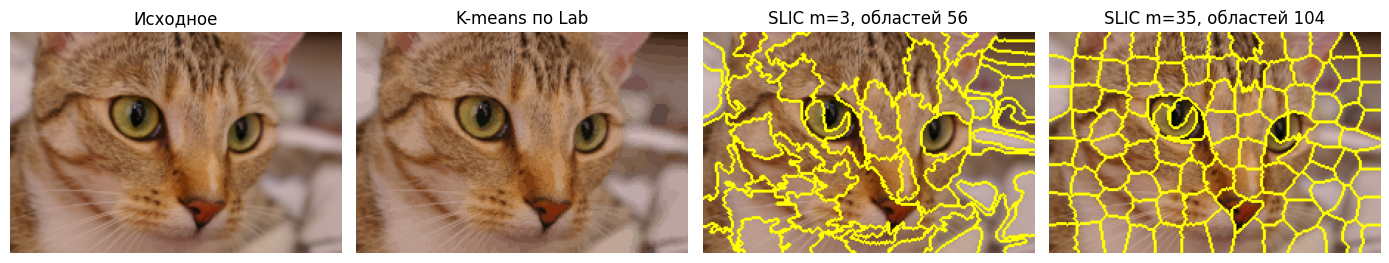

In [ ]:
cat = transform.resize(data.chelsea(), (150, 225), anti_aliasing=True)
lab = color.rgb2lab(cat)
samples = lab.reshape(-1, 3).astype(np.float32)

cv2.setRNGSeed(8)
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.1)
_, assignments, centers = cv2.kmeans(samples, 100, None, criteria, 3, cv2.KMEANS_PP_CENTERS)
label_map = assignments.reshape(cat.shape[:2])
quantized = color.lab2rgb(centers[label_map])
n_pieces = sum(n_regions(measure.label(label_map == k, connectivity=2)) for k in range(4))

compactness_values = (3, 35)
superpixels = [
    segmentation.slic(cat, n_segments=110, compactness=m, start_label=1, channel_axis=-1)
    for m in compactness_values
]
overlays = [segmentation.mark_boundaries(cat, labels) for labels in superpixels]
print(f"K-means: 4 цветовых кластера, {n_pieces} связных участков.")
show(cat, quantized, *overlays,
     titles=["Исходное", "K-means по Lab"] +
            [f"SLIC m={m}, областей {n_regions(labels)}"
             for m, labels in zip(compactness_values, superpixels)],
     figsize=(14, 3.4))

## 5. Активные контуры · дополнительно

Активный контур эволюционирует, чтобы уменьшить энергию. В варианте Chan–Vese один из критериев — насколько яркости внутри и снаружи близки к своим средним. Это даёт способ выделять области со слабыми границами. Параметр `mu` усиливает штраф за длину границы. Сравните, что происходит с тонким выступом и возникают ли лишние области у края кадра. Результат зависит и от начального контура.

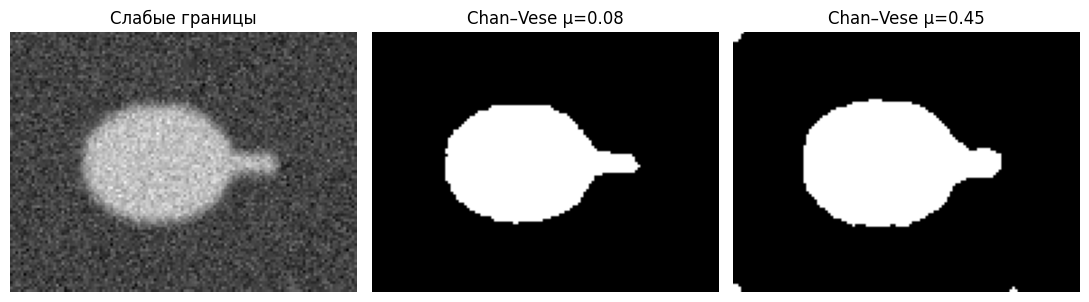

In [ ]:
y, x = np.ogrid[:96, :128]
blob = (y - 48) ** 2 / 22 ** 2 + (x - 54) ** 2 / 28 ** 2 < 1
blob |= (x >= 75) & (x < 98) & (np.abs(y - 48) <= 3)
rng = np.random.default_rng(18)
weak_edges = ndi.gaussian_filter(np.where(blob, 0.58, 0.40), sigma=1.8)
weak_edges = np.clip(weak_edges + rng.normal(0, 0.025, blob.shape), 0, 1)
cv_lo = segmentation.chan_vese(weak_edges, mu=0.08, max_num_iter=200)
cv_hi = segmentation.chan_vese(weak_edges, mu=0.45, max_num_iter=200)
show(weak_edges, cv_lo, cv_hi, titles=["Слабые границы", "Chan–Vese μ=0.08", "Chan–Vese μ=0.45"],
     cmaps=["gray"] * 3, figsize=(11, 3))

## 6. Графовые методы и интерактивный GrabCut

В бинарном graph cut слагаемое соответствия данным оценивает согласие метки с яркостью, а штраф на соседних пикселях ограничивает число резких смен метки. Сравним две разметки. Здесь вес каждой соседней пары одинаков. В GrabCut соответствие данным оценивают смеси гауссиан по цвету, а вес по границе зависит от цветового перепада.

In [ ]:
row = np.array([40, 60, 150, 50, 190, 210, 200])
by_intensity = np.array([0, 0, 1, 0, 1, 1, 1])
smooth = np.array([0, 0, 0, 0, 1, 1, 1])

for name, labels in [("По яркости", by_intensity), ("Сглаженная", smooth)]:
    data_cost = np.abs(row - np.where(labels == 1, 200, 50)).sum() / 10
    transitions = np.count_nonzero(labels[1:] != labels[:-1])
    print(f"{name:12s}: данных {data_cost:2.0f}, границ {transitions}, "
          f"E(λ=0)={data_cost:.0f}, E(λ=4)={data_cost + 4 * transitions:.0f}")

По яркости  : данных  9, границ 3, E(λ=0)=9, E(λ=4)=21
Сглаженная  : данных 14, границ 1, E(λ=0)=14, E(λ=4)=18


На фотографии `astronaut` сначала зададим только рамку. Затем добавим несколько мазков уверенного фона и объекта и уточним маску. Измените один мазок, посмотрите на ошибку в результате и объясните, почему она появилась. В OpenCV координаты точек задаются как $(x,y)$, а прямоугольник — как $(x,y,w,h)$.

Метка изменилась у 2.2% пикселей.


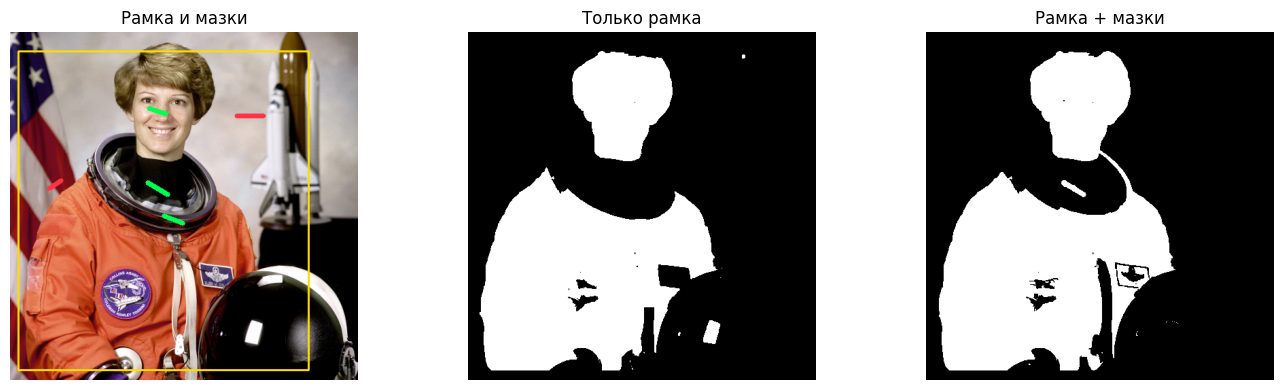

In [ ]:
def is_foreground(labels):
    return (labels == cv2.GC_FGD) | (labels == cv2.GC_PR_FGD)

astro = data.astronaut()
astro_bgr = cv2.cvtColor(astro, cv2.COLOR_RGB2BGR)
rect = (12, 28, 428, 470)
grab_labels = np.zeros(astro.shape[:2], np.uint8)
background_model = np.zeros((1, 65), np.float64)
foreground_model = np.zeros((1, 65), np.float64)
cv2.setRNGSeed(8)
cv2.grabCut(astro_bgr, grab_labels, rect, background_model, foreground_model, 4, cv2.GC_INIT_WITH_RECT)
grab_initial = is_foreground(grab_labels)

prompt_view = astro.copy()
cv2.rectangle(prompt_view, rect, (255, 220, 0), 2)
strokes = [
    ((204, 112), (229, 120), cv2.GC_FGD, (0, 255, 80)),
    ((226, 270), (254, 281), cv2.GC_FGD, (0, 255, 80)),
    ((202, 221), (232, 239), cv2.GC_FGD, (0, 255, 80)),
    ((333, 123), (373, 123), cv2.GC_BGD, (255, 50, 70)),
    ((57, 230), (75, 218), cv2.GC_BGD, (255, 50, 70)),
]
for start, end, label, rgb in strokes:
    cv2.line(grab_labels, start, end, label, 5)
    cv2.line(prompt_view, start, end, rgb, 5)

cv2.grabCut(astro_bgr, grab_labels, None, background_model, foreground_model, 4, cv2.GC_INIT_WITH_MASK)
grab_refined = is_foreground(grab_labels)
print(f"Метка изменилась у {(grab_initial != grab_refined).mean():.1%} пикселей.")
show(prompt_view, grab_initial, grab_refined,
     titles=["Рамка и мазки", "Только рамка", "Рамка + мазки"],
     cmaps=[None, "gray", "gray"])

## 7. Оценка качества

Для бинарного эталона $A$ и предсказания $B$:
$\operatorname{IoU}=|A\cap B|/|A\cup B|$,
$\operatorname{Dice}=2|A\cap B|/(|A|+|B|)$.
В этом ноутбуке для двух пустых масок обе метрики равны 1. Pixel accuracy учитывает и фон. При маленьком объекте пустая маска может получить высокую accuracy при нулевом IoU.

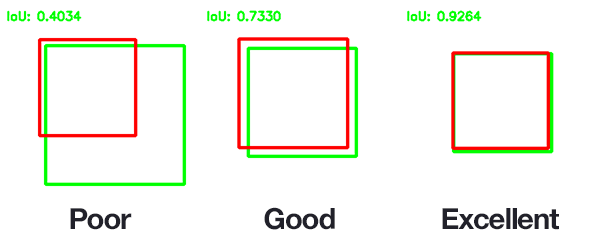

In [ ]:
def binary_iou(a, b):
    a = np.asarray(a, dtype=bool)
    b = np.asarray(b, dtype=bool)
    inter = np.logical_and(a, b).sum()
    union = np.logical_or(a, b).sum()
    if union == 0:
        return 1.0
    return float(inter / union)


def binary_dice(a, b):
    a = np.asarray(a, dtype=bool)
    b = np.asarray(b, dtype=bool)
    inter = np.logical_and(a, b).sum()
    s = a.sum() + b.sum()
    if s == 0:
        return 1.0
    return float(2.0 * inter / s)


def pixel_accuracy(truth, pred):
    truth = np.asarray(truth, dtype=bool)
    pred = np.asarray(pred, dtype=bool)
    return np.mean(truth == pred)

Объект занимает 1.2% кадра.
Пустая маска: accuracy=0.988, IoU=0.000, Dice=0.000


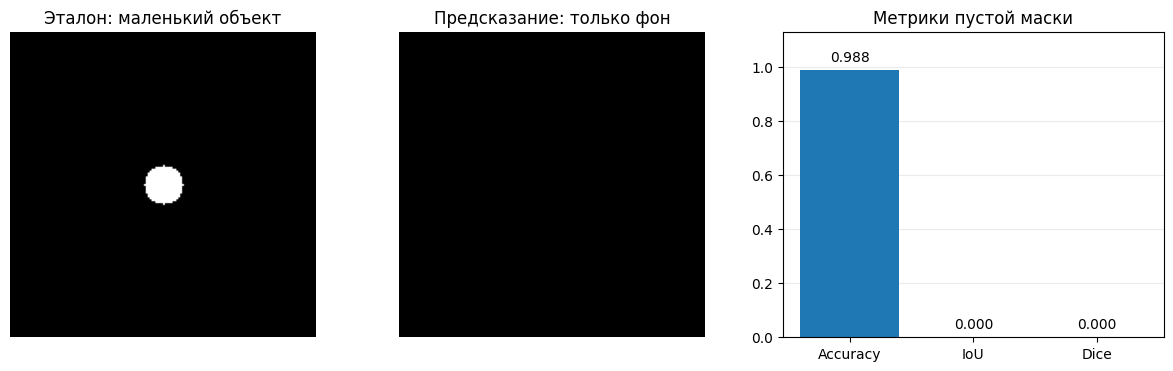

In [ ]:
yy, xx = np.ogrid[:160, :160]
small_object = (yy - 80) ** 2 + (xx - 80) ** 2 <= 10 ** 2
empty_prediction = np.zeros_like(small_object)
print(f"Объект занимает {small_object.mean():.1%} кадра.")
print(f"Пустая маска: accuracy={pixel_accuracy(small_object, empty_prediction):.3f}, "
      f"IoU={binary_iou(small_object, empty_prediction):.3f}, "
      f"Dice={binary_dice(small_object, empty_prediction):.3f}")

scores = [
    pixel_accuracy(small_object, empty_prediction),
    binary_iou(small_object, empty_prediction),
    binary_dice(small_object, empty_prediction),
]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout="constrained")

for ax, mask, title in zip(
    axes[:2],
    (small_object, empty_prediction),
    ("Эталон: маленький объект", "Предсказание: только фон"),
):
    ax.imshow(mask, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

ax = axes[2]
bars = ax.bar(["Accuracy", "IoU", "Dice"], scores)
ax.bar_label(bars, labels=[f"{score:.3f}" for score in scores], padding=4)
ax.set(
    ylim=(0, 1.13),
    yticks=np.linspace(0, 1, 6),
    title="Метрики пустой маски",
)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)

plt.show()

Объект занимает 1.2% кадра.
Accuracy=0.994, IoU=0.605, Dice=0.754


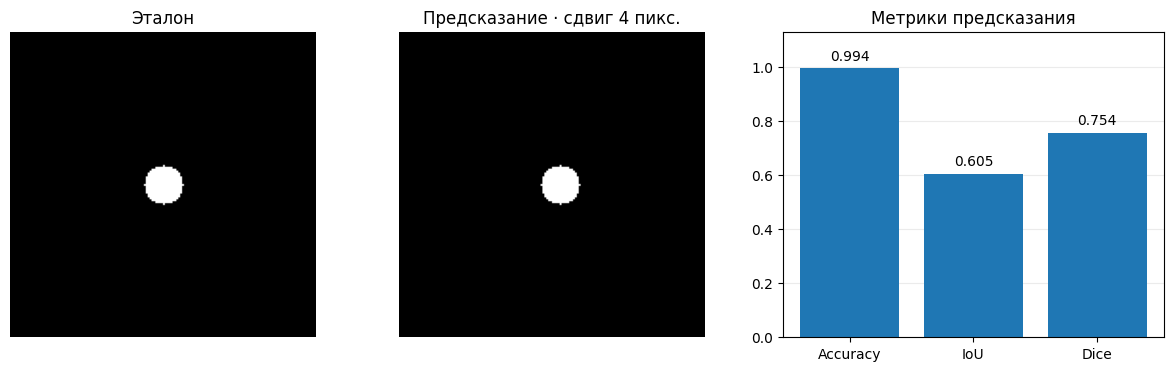

In [ ]:
yy, xx = np.ogrid[:160, :160]
small_object = (yy - 80) ** 2 + (xx - 80) ** 2 <= 10 ** 2

shift = 4
prediction = (yy - 80) ** 2 + (xx - (80 + shift)) ** 2 <= 10 ** 2

scores = [
    pixel_accuracy(small_object, prediction),
    binary_iou(small_object, prediction),
    binary_dice(small_object, prediction),
]

print(f"Объект занимает {small_object.mean():.1%} кадра.")
print(f"Accuracy={scores[0]:.3f}, IoU={scores[1]:.3f}, Dice={scores[2]:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout="constrained")

for ax, mask, title in zip(
    axes[:2],
    (small_object, prediction),
    ("Эталон", f"Предсказание · сдвиг {shift} пикс."),
):
    ax.imshow(mask, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

ax = axes[2]
bars = ax.bar(["Accuracy", "IoU", "Dice"], scores)
ax.bar_label(bars, labels=[f"{score:.3f}" for score in scores], padding=4)
ax.set(
    ylim=(0, 1.13),
    yticks=np.linspace(0, 1, 6),
    title="Метрики предсказания",
)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)

plt.show()

## 8. Самостоятельная работа · разделение объектов

Даны две бинарные сцены со слипшимися дисками разных размеров. На сцене A есть также отдельный диск. Реализуйте `split_objects`: функция принимает только бинарную маску и возвращает карту меток объектов с фоном 0.

1. Сравните две сцены для связных компонент и своего метода. Используйте **одну настройку или одно правило подбора параметров** для обеих сцен.
2. Для каждой сцены запишите IoU общей маски и абсолютную ошибку числа объектов. Покажите цветные карты меток.
3. Проведите один контрольный эксперимент, изменив правило или параметр маркеров. Опишите, где произошли слияние или дробление и как это отразилось на обеих метриках.

Эталонное число объектов используйте только при оценке. Две карты меток могут давать одинаковый IoU маски и разное число объектов.

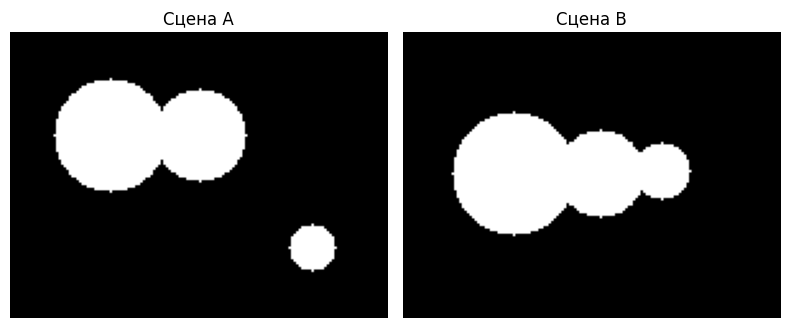

In [ ]:
def disk_scene(disks):
    y, x = np.ogrid[:112, :148]
    masks = [(y - cy) ** 2 + (x - cx) ** 2 <= r ** 2 for cy, cx, r in disks]
    return np.logical_or.reduce(masks), len(disks)


scenes = {
    "A": disk_scene([(40, 39, 22), (40, 74, 18), (84, 118, 9)]),
    "B": disk_scene([(55, 43, 24), (55, 77, 17), (54, 101, 11)]),
}
show(*(mask for mask, _ in scenes.values()), titles=["Сцена A", "Сцена B"],
     cmaps=["gray", "gray"], figsize=(8, 3.4))

## Материалы

- Тумаков, Каюмов, Егорчев и др. [Алгоритмические методы сегментации изображений. КФУ, 2023](https://kpfu.ru/portal/docs/F265768322/Algoritmicheskie.metody.segmentacii.izobrazhenii_.pdf).
- scikit-image. [Niblack и Sauvola](https://scikit-image.org/docs/stable/auto_examples/segmentation/plot_niblack_sauvola.html), [монеты](https://scikit-image.org/docs/stable/auto_examples/applications/plot_coins_segmentation.html), [разделение дисков](https://scikit-image.org/docs/stable/auto_examples/segmentation/plot_watershed.html), [сравнение суперпикселей](https://scikit-image.org/docs/stable/auto_examples/segmentation/plot_segmentations.html).
- OpenCV. [Интерактивное выделение объекта с GrabCut](https://docs.opencv.org/4.x/d8/d83/tutorial_py_grabcut.html).